In [1]:
from IPython.display import display, HTML
display(HTML("<style>.jp-OutputArea-output { max-height: none !important; overflow: visible !important; }</style>"))

# Домашняя работа 1.3 - ClickHouse

In [2]:
import os
import clickhouse_connect
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import random
import time

# Docker: ch11; local Python: localhost.
client = clickhouse_connect.get_client(
    host=os.getenv('CLICKHOUSE_HOST', 'localhost'),
    port=int(os.getenv('CLICKHOUSE_PORT', '8123')),
    username=os.getenv('CLICKHOUSE_USER', 'default'),
    password=os.getenv('CLICKHOUSE_PASSWORD', 'homework'),
    send_receive_timeout=600,
    settings={'max_threads': 1, 'max_block_size': 32768, 'max_insert_block_size': 32768,
              'max_bytes_before_external_group_by': 67108864,
              'join_algorithm': 'grace_hash', 'max_bytes_in_join': 67108864},
)
print('ClickHouse version:', client.query('SELECT version()').first_row[0])


ClickHouse version: 25.8.33.6


In [3]:
# Полный запуск с нуля: пересоздаются только учебные базы этого ноутбука.
RUN_NOW = datetime(2026, 10, 8, 12, 0, 0)
RUN_DATE = RUN_NOW.date()
print("Расчётная дата:", RUN_DATE)
cluster_clients = [clickhouse_connect.get_client(
    host=host, port=8123, username='default', password='homework', send_receive_timeout=600,
) for host in ('ch11', 'ch12', 'ch21', 'ch22')]
client.command("DROP DATABASE IF EXISTS hw ON CLUSTER homework_cluster SYNC")
client.command("DROP DATABASE IF EXISTS homework_data ON CLUSTER homework_cluster SYNC")


Расчётная дата: 2026-10-08


['ch21',
 '9000',
 '0',
 '',
 '3',
 '2\nch11',
 '9000',
 '0',
 '',
 '2',
 '2\nch12',
 '9000',
 '0',
 '',
 '1',
 '1\nch22',
 '9000',
 '0',
 '',
 '0',
 '0']

In [4]:
client.query_df("""
SELECT cluster, shard_num, replica_num, host_name, port
FROM system.clusters
WHERE cluster = 'homework_cluster'
ORDER BY shard_num, replica_num
""")


,cluster,shard_num,replica_num,host_name,port
0,homework_cluster,1,1,ch11,9000
1,homework_cluster,1,2,ch12,9000
2,homework_cluster,2,1,ch21,9000
3,homework_cluster,2,2,ch22,9000


In [5]:
client.query_df("""
SELECT hostName() AS host, version() AS version
FROM clusterAllReplicas('homework_cluster', system.one)
ORDER BY host
""")


,host,version
0,ch11,25.8.33.6
1,ch12,25.8.33.6
2,ch21,25.8.33.6
3,ch22,25.8.33.6


# Задание 1 - Raw слой

In [6]:
# Создаём базу данных на всём кластере
client.command("""
CREATE DATABASE IF NOT EXISTS hw ON CLUSTER homework_cluster
""")
print("База данных hw создана")

База данных hw создана


In [7]:
# Создаём локальную таблицу на всех нодах
# {shard} и {replica} заменяются из macros.xml каждой ноды
client.command("""
CREATE TABLE IF NOT EXISTS hw.events_local ON CLUSTER homework_cluster
(
    event_date      Date,
    event_time      DateTime,
    user_id         UInt64,
    event_type      LowCardinality(String),
    platform        LowCardinality(String),
    country         LowCardinality(String),
    value           Float64,
    session_id      String
)
ENGINE = ReplicatedMergeTree(
    '/clickhouse/tables/{shard}/hw/events_local',
    '{replica}'
)
PARTITION BY toYYYYMMDD(event_date)
ORDER BY (user_id, event_type, event_time)
TTL event_date + INTERVAL 30 DAY
""")
print("Локальная таблица events_local создана на всех нодах")

Локальная таблица events_local создана на всех нодах


Локальная таблица events_local создана на всех нодах

Партицирование по дню

In [8]:
# Создаём Distributed таблицу — точка входа для запросов
client.command("""
CREATE TABLE IF NOT EXISTS hw.events ON CLUSTER homework_cluster
AS hw.events_local
ENGINE = Distributed(
    'homework_cluster',      -- кластер
    'hw',              -- база данных
    'events_local',     -- локальная таблица
    rand()              -- sharding key — равномерное распределение
)
""")
print("Distributed таблица events создана")

Distributed таблица events создана


## Вставляем данные

In [9]:
# Генерируем тестовые данные
random.seed(42)

event_types = ['click', 'view', 'purchase', 'add_to_cart', 'search', 'logout']
platforms   = ['ios', 'android', 'web']
countries   = ['RU', 'US', 'DE', 'FR', 'BR', 'CN', 'IN']

rows = []
base_date = RUN_NOW.replace(hour=0, minute=0, second=0) - timedelta(days=6)

for i in range(1_000_000):  # 1 миллион событий
    event_time = base_date + timedelta(
        days=random.randint(0, 6),
        hours=random.randint(0, 23),
        minutes=random.randint(0, 59)
    )
    rows.append((
        event_time.date(),
        event_time,
        random.randint(1, 100_000),
        random.choice(event_types),
        random.choice(platforms),
        random.choice(countries),
        round(random.uniform(0, 1000), 2),
        f'sess_{random.randint(1, 500_000)}'
    ))

print(f"Сгенерировано {len(rows):,} строк")
print(f"Пример строки: {rows[0]}")

Сгенерировано 1,000,000 строк
Пример строки: (datetime.date(2026, 10, 7), datetime.datetime(2026, 10, 7, 3, 1), 97197, 'purchase', 'ios', 'US', 139.54, 'sess_53737')


In [10]:
# Вставляем батчем в Distributed таблицу
# CH сам распределит данные по шардам через rand()
start = time.time()

client.insert(
    'hw.events',
    rows,
    column_names=[
        'event_date', 'event_time', 'user_id', 'event_type',
        'platform', 'country', 'value', 'session_id'
    ]
)

elapsed = time.time() - start
print(f"Вставлено {len(rows):,} строк за {elapsed:.2f} сек")
print(f"Скорость: {len(rows)/elapsed:,.0f} строк/сек")

Вставлено 1,000,000 строк за 4.02 сек
Скорость: 249,003 строк/сек


In [11]:
# Смотрим как данные распределились по шардам
df = client.query_df("""
SELECT
    hostName()                              AS host,
    count()                                 AS parts,
    formatReadableQuantity(sum(rows))       AS total_rows,
    formatReadableSize(sum(bytes_on_disk))  AS size_on_disk
FROM clusterAllReplicas('homework_cluster', system.parts)
WHERE active
  AND database = 'hw'
  AND table = 'events_local'
GROUP BY host
ORDER BY host
""")
print("Распределение данных по шардам:")
print(df.to_string(index=False))

Распределение данных по шардам:
host  parts      total_rows size_on_disk
ch11      7 500.46 thousand     9.06 MiB
ch12      7 500.46 thousand     9.06 MiB
ch21      7 499.54 thousand     9.04 MiB
ch22      7 499.54 thousand     9.04 MiB


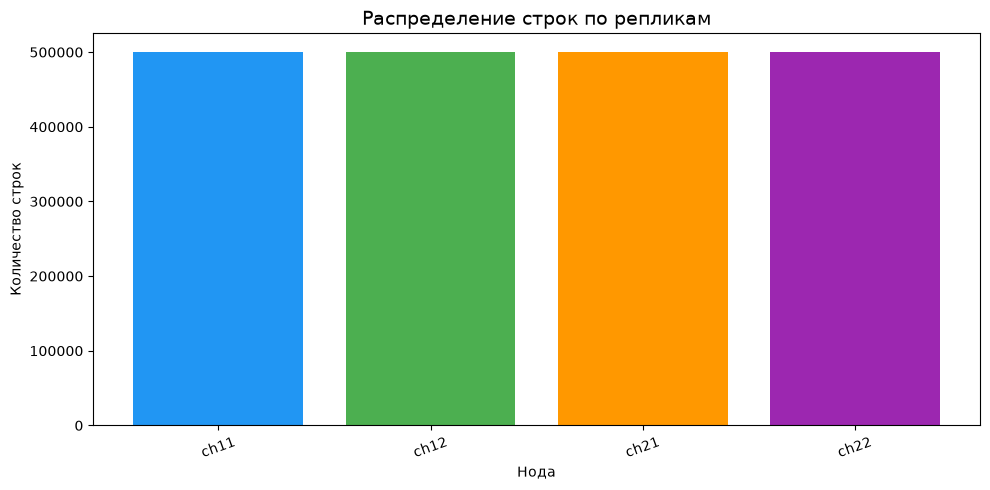

In [12]:
# Визуализируем распределение
df_vis = client.query_df("""
SELECT
    hostName()  AS host,
    sum(rows)   AS total_rows
FROM clusterAllReplicas('homework_cluster', system.parts)
WHERE active
  AND database = 'hw'
  AND table = 'events_local'
GROUP BY host
ORDER BY host
""")

plt.figure(figsize=(10, 5))
plt.bar(df_vis['host'], df_vis['total_rows'], color=['#2196F3', '#4CAF50', '#FF9800', '#9C27B0'])
plt.title('Распределение строк по репликам', fontsize=14)
plt.xlabel('Нода')
plt.ylabel('Количество строк')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [13]:
df = client.query_df("""
SELECT count(*) from hw.events_local
""")
print(df.to_string(index=False))

 count()
  500460


In [14]:
df = client.query_df("""
SELECT count(*) from hw.events
""")
print(df.to_string(index=False))

 count()
 1000000


In [15]:
df = client.query_df("""
SELECT count(*) from clusterAllReplicas('homework_cluster', 'hw.events_local')
""")
print(df.to_string(index=False))

 count()
 2000000


### Проверки

In [16]:
result = client.query("""
SELECT hostName(), count()
FROM clusterAllReplicas('homework_cluster', hw.events_local)
GROUP BY hostName()
""")
print(result.result_rows)

[('ch21', 499540), ('ch11', 500460), ('ch22', 499540), ('ch12', 500460)]


In [17]:
result = client.query("""
SELECT
    database,
    table,
    is_readonly,
    absolute_delay,
    log_pointer
FROM clusterAllReplicas('homework_cluster', system.replicas)
WHERE database = 'hw'
""")
print(result.result_rows)

[('hw', 'events_local', 0, 0, 7), ('hw', 'events_local', 0, 0, 7), ('hw', 'events_local', 0, 0, 7), ('hw', 'events_local', 0, 0, 7)]


**Что будет, если вставлять в локальную таблицу, а не в Distributed?**

Данные лягут только на один шард, кластер будет работать кое как

# Задание 2 - Агрегаты (AggregatingMergeTree + MV)

Локальная agg таблица

In [18]:
client.command("""
CREATE TABLE IF NOT EXISTS hw.push_events_agg_local ON CLUSTER homework_cluster
(
    event_date   Date,
    platform     LowCardinality(String),
    cnt          AggregateFunction(count),
    uniq_users   AggregateFunction(uniq, UInt64),
    avg_latency  AggregateFunction(avg, Float64)
)
ENGINE = ReplicatedAggregatingMergeTree('/clickhouse/tables/{shard}/hw/push_events_agg_local', '{replica}')
PARTITION BY toYYYYMMDD(event_date)
ORDER BY (event_date, platform)
""")
print("push_events_agg_local создана")

push_events_agg_local создана


Distributed таблица

In [19]:
client.command("""
CREATE TABLE IF NOT EXISTS hw.push_events_agg ON CLUSTER homework_cluster
AS hw.push_events_agg_local
ENGINE = Distributed(
    'homework_cluster',
    'hw',
    'push_events_agg_local',
    rand()
)
""")
print("push_events_agg создана")

push_events_agg создана


push_events_raw

In [20]:
client.command("""
CREATE TABLE IF NOT EXISTS hw.push_events_raw_local ON CLUSTER homework_cluster
(
    event_date   Date,
    event_time   DateTime,
    user_id      UInt64,
    platform     LowCardinality(String),
    latency_ms   Float64,
    status       String
)
ENGINE = ReplicatedMergeTree('/clickhouse/tables/{shard}/hw/push_events_raw_local', '{replica}')
PARTITION BY toYYYYMMDD(event_date)
ORDER BY (event_date, platform, user_id)
""")

print("push_events_raw создана")
client.command("""
CREATE TABLE IF NOT EXISTS hw.push_events_raw ON CLUSTER homework_cluster
AS hw.push_events_raw_local
ENGINE = Distributed('homework_cluster', 'hw', 'push_events_raw_local', cityHash64(platform))
""")


push_events_raw создана


['ch21',
 '9000',
 '0',
 '',
 '3',
 '0\nch11',
 '9000',
 '0',
 '',
 '2',
 '0\nch22',
 '9000',
 '0',
 '',
 '1',
 '0\nch12',
 '9000',
 '0',
 '',
 '0',
 '0']

MV

In [21]:
client.command("""
CREATE MATERIALIZED VIEW IF NOT EXISTS hw.push_events_agg_mv
ON CLUSTER homework_cluster
TO hw.push_events_agg_local
AS
SELECT
    event_date,
    platform,
    countState()          AS cnt,
    uniqState(user_id)    AS uniq_users,
    avgState(latency_ms)  AS avg_latency
FROM hw.push_events_raw_local
GROUP BY event_date, platform
""")
print("push_events_agg_mv создана")

push_events_agg_mv создана


In [22]:
for row in client.query("SHOW TABLES FROM hw").result_rows:
    print(row)

('events',)
('events_local',)
('push_events_agg',)
('push_events_agg_local',)
('push_events_agg_mv',)
('push_events_raw',)
('push_events_raw_local',)


**Вставка небольшого набора данных двумя отдельными батчами**

In [23]:
# Защита от случайного повторного выполнения.
assert client.query(
    "SELECT count() FROM hw.push_events_raw"
).first_row[0] == 0, "Raw уже содержит данные"

assert client.query(
    "SELECT count() FROM hw.push_events_agg_local"
).first_row[0] == 0, "Агрегаты уже содержат данные"

t = RUN_NOW
d = t.date()

batch_1 = [
    (d, t, 1, 'ANDROID', 10.0, 'delivered'),
    (d, t, 2, 'ANDROID', 30.0, 'opened'),
    (d, t, 1, 'WEB',    100.0, 'delivered'),
]

batch_2 = [
    (d, t, 1, 'ANDROID', 20.0, 'opened'),
    (d, t, 3, 'ANDROID', 20.0, 'failed'),
    (d, t, 2, 'WEB',    200.0, 'opened'),
]

columns = [
    'event_date', 'event_time', 'user_id',
    'platform', 'latency_ms', 'status',
]

for batch in (batch_1, batch_2):
    client.insert(
        'hw.push_events_raw',
        batch,
        column_names=columns,
    )

print("Вставлено 6 событий")

Вставлено 6 событий


**Чтение через Merge и сравнение с raw**

In [24]:
agg = client.query_df("""
SELECT
    event_date,
    platform,
    countMerge(cnt) AS cnt,
    uniqMerge(uniq_users) AS uniq_users,
    avgMerge(avg_latency) AS avg_latency
FROM hw.push_events_agg
GROUP BY event_date, platform
ORDER BY event_date, platform
""")

raw = client.query_df("""
SELECT
    event_date,
    platform,
    count() AS cnt,
    uniq(user_id) AS uniq_users,
    avg(latency_ms) AS avg_latency
FROM hw.push_events_raw
GROUP BY event_date, platform
ORDER BY event_date, platform
""")

display(agg)
display(raw)

pd.testing.assert_frame_equal(
    agg,
    raw,
    check_exact=False,
    rtol=1e-10,
    atol=1e-10,
)
print("Результаты совпадают")

,event_date,platform,cnt,uniq_users,avg_latency
0,2026-10-08,ANDROID,4,3,20.0
1,2026-10-08,WEB,2,2,150.0


,event_date,platform,cnt,uniq_users,avg_latency
0,2026-10-08,ANDROID,4,3,20.0
1,2026-10-08,WEB,2,2,150.0


Результаты совпадают


**Проверка созданной Distributed-таблицы**

In [25]:
client.query_df("""
SELECT
    event_date,
    platform,
    countMerge(cnt) AS cnt,
    uniqMerge(uniq_users) AS uniq_users,
    avgMerge(avg_latency) AS avg_latency
FROM hw.push_events_agg
GROUP BY event_date, platform
ORDER BY event_date, platform
SETTINGS prefer_localhost_replica = 1
""")

,event_date,platform,cnt,uniq_users,avg_latency
0,2026-10-08,ANDROID,4,3,20.0
1,2026-10-08,WEB,2,2,150.0


**Физическое схлопывание строк**

In [26]:
def physical_rows():
    return client.query("SELECT count() FROM hw.push_events_agg_local").first_row[0]

before = physical_rows()

client.command("""
OPTIMIZE TABLE hw.push_events_agg_local FINAL
""")

after = physical_rows()

print("Строк состояний до:", before)
print("Строк состояний после:", after)
expected_local_groups = client.query("SELECT count() FROM (SELECT event_date, platform FROM hw.push_events_raw_local GROUP BY event_date, platform)").first_row[0]
assert after == expected_local_groups

Строк состояний до: 4
Строк состояний после: 2


**Проверка avgMerge без GROUP BY**

In [27]:
client.query_df("""
SELECT
    (SELECT avgMerge(avg_latency)
     FROM hw.push_events_agg) AS avg_from_states,

    (SELECT avg(latency_ms)
     FROM hw.push_events_raw) AS avg_from_raw
""")

,avg_from_states,avg_from_raw
0,63.333333,63.333333


Если MV создать после вставки данных: существующие строки автоматически не попадут в агрегаты

avgMerge без GROUP BY вернте одно общее среднее по всем объединённым состояниям - это корректное среднее исходных событий, потому что состояние среднего хранит сумму и количество.

# Задание 3 - Counters (SummingMergeTree + MV)

 требуемая push_counters_loca

In [28]:
client.command("""
CREATE TABLE IF NOT EXISTS hw.push_counters_local ON CLUSTER homework_cluster
(
    event_date Date,
    platform LowCardinality(String),
    user_id UInt64,
    delivered_count UInt64,
    failed_count UInt64,
    opened_count UInt64
)
ENGINE = ReplicatedSummingMergeTree('/clickhouse/tables/{shard}/hw/push_counters_local', '{replica}')
PARTITION BY toYYYYMMDD(event_date)
ORDER BY (event_date, platform)
""")
print("push_counters_local создана")

push_counters_local создана


In [29]:
client.command("""
CREATE TABLE IF NOT EXISTS hw.push_counters ON CLUSTER homework_cluster
AS hw.push_counters_local
ENGINE = Distributed('homework_cluster', 'hw', 'push_counters_local', rand())
""")
print("push_counters создана")

push_counters создана


MV считает каждый новый блок raw. min(user_id) это минимальный пользователь в группе данного блока, а не пользователь всех событий группы

In [30]:
client.command("""
CREATE MATERIALIZED VIEW IF NOT EXISTS hw.push_counters_mv
ON CLUSTER homework_cluster
TO hw.push_counters_local
AS SELECT
    event_date,
    platform,
    min(user_id) AS user_id,
    countIf(status = 'delivered') AS delivered_count,
    countIf(status = 'failed') AS failed_count,
    countIf(status = 'opened') AS opened_count
FROM hw.push_events_raw_local
GROUP BY event_date, platform
""")
print("push_counters_mv создана")

push_counters_mv создана


Вставляем два новых батча. Выбираем дату, которой ещё нет в raw. Проверяем пустоту counters, чтобы повторный запуск не добавил события снова.

In [31]:
from datetime import datetime, timedelta

assert client.query("SELECT count() FROM hw.push_counters_local").first_row[0] == 0, "Counters уже содержит данные — не повторяйте вставку"
task3_date = RUN_DATE
while client.query(
    "SELECT count() FROM hw.push_events_raw WHERE event_date = {d:Date}",
    parameters={'d': task3_date},
).first_row[0]:
    task3_date -= timedelta(days=1)
task3_time = datetime.combine(task3_date, datetime.min.time())

task3_batch_1 = [
    (task3_date, task3_time, 10, 'ANDROID', 10.0, 'delivered'),
    (task3_date, task3_time, 11, 'ANDROID', 30.0, 'opened'),
    (task3_date, task3_time, 100, 'WEB', 100.0, 'delivered'),
]
task3_batch_2 = [
    (task3_date, task3_time, 20, 'ANDROID', 20.0, 'failed'),
    (task3_date, task3_time, 21, 'ANDROID', 20.0, 'opened'),
    (task3_date, task3_time, 200, 'WEB', 200.0, 'opened'),
]
task3_columns = ['event_date', 'event_time', 'user_id', 'platform', 'latency_ms', 'status']

for node in cluster_clients:
    node.command("SYSTEM STOP MERGES hw.push_counters_local")
try:
    for batch in (task3_batch_1, task3_batch_2):
        client.insert('hw.push_events_raw', batch, column_names=task3_columns)
    task3_before = client.query_df("""
        SELECT * FROM hw.push_counters
        WHERE event_date = {d:Date}
        ORDER BY event_date, platform, user_id
        SETTINGS prefer_localhost_replica = 1
    """, parameters={'d': task3_date})
finally:
    for node in cluster_clients:
        node.command("SYSTEM START MERGES hw.push_counters_local")

print("Дата теста:", task3_date)
print("SELECT * до слияния — снимок, сохранённый при остановленных merge:")
display(task3_before)
assert len(task3_before) == 4

Дата теста: 2026-10-07
SELECT * до слияния — снимок, сохранённый при остановленных merge:


,event_date,platform,user_id,delivered_count,failed_count,opened_count
0,2026-10-07,ANDROID,10,1,0,1
1,2026-10-07,ANDROID,20,0,1,1
2,2026-10-07,WEB,100,1,0,0
3,2026-10-07,WEB,200,0,0,1


Проверяем счётчики до OPTIMIZE

In [32]:
task3_counter_sql = """
SELECT event_date, platform,
    sum(delivered_count) AS delivered_count,
    sum(failed_count) AS failed_count,
    sum(opened_count) AS opened_count
FROM hw.push_counters
WHERE event_date = {d:Date}
GROUP BY event_date, platform
ORDER BY event_date, platform
SETTINGS prefer_localhost_replica = 1
"""
task3_counters = client.query_df(task3_counter_sql, parameters={'d': task3_date})
task3_raw = client.query_df("""
SELECT event_date, platform,
    countIf(status = 'delivered') AS delivered_count,
    countIf(status = 'failed') AS failed_count,
    countIf(status = 'opened') AS opened_count
FROM hw.push_events_raw
WHERE event_date = {d:Date}
GROUP BY event_date, platform
ORDER BY event_date, platform
""", parameters={'d': task3_date})
display(task3_counters)
display(task3_raw)
pd.testing.assert_frame_equal(task3_counters, task3_raw)
print("Счётчики совпадают с raw")

,event_date,platform,delivered_count,failed_count,opened_count
0,2026-10-07,ANDROID,1,1,2
1,2026-10-07,WEB,1,0,1


,event_date,platform,delivered_count,failed_count,opened_count
0,2026-10-07,ANDROID,1,1,2
1,2026-10-07,WEB,1,0,1


Счётчики совпадают с raw


In [33]:
for node in cluster_clients:
    node.command("OPTIMIZE TABLE hw.push_counters_local FINAL")
    node.command("SYSTEM SYNC REPLICA hw.push_counters_local")
task3_after = client.query_df("""
SELECT * FROM hw.push_counters
WHERE event_date = {d:Date}
ORDER BY event_date, platform
SETTINGS prefer_localhost_replica = 1
""", parameters={'d': task3_date})
print("SELECT * после OPTIMIZE FINAL:")
display(task3_after)
assert len(task3_after) == 2
assert task3_after['user_id'].tolist() == [30, 300]

task3_after_counters = client.query_df(task3_counter_sql, parameters={'d': task3_date})
pd.testing.assert_frame_equal(task3_after_counters, task3_raw)
print("Счётчики сохранились; user_id ошибочно сложились: 10 + 20 = 30, 100 + 200 = 300")

SELECT * после OPTIMIZE FINAL:


,event_date,platform,user_id,delivered_count,failed_count,opened_count
0,2026-10-07,ANDROID,30,1,1,2
1,2026-10-07,WEB,300,1,0,1


Счётчики сохранились; user_id ошибочно сложились: 10 + 20 = 30, 100 + 200 = 300


**Что не так с user_id после OPTIMIZE FINAL?**

У ANDROID user_id стал 30, у WEB - 300. Это суммы минимумов пользователей двух батчей, а не реальные идентификаторы этих событий. Без явно заданного списка колонок SummingMergeTree суммирует подходящие числовые колонки вне ключа сортировки, включая user_id

**Два варианта исправления:**

1. Если нужны счётчики по (день, платформа), убрать user_id из целевой таблицы и MV. Можно явно задать ENGINE = SummingMergeTree((delivered_count, failed_count, opened_count)), чтобы суммировались только счётчики.
2. Если нужны счётчики каждого пользователя, изменить детализацию: ORDER BY (event_date, platform, user_id), а в MV выбирать user_id без min и группировать GROUP BY event_date, platform, user_id. Для отчёта по платформе затем суммировать счётчики по (event_date, platform).

Только исключить user_id из списка суммируемых колонок, оставив вне ключа, недостаточно: движок выберет произвольное значение из объединяемых строк, и оно не будет описывать всю группу.

**Почему нельзя хранить avg как обычное число в SummingMergeTree?**

Средние не складываются. Для батчей [10, 30] и [100] средние равны 20 и 100. Их сумма - 120, среднее средних - 60, а среднее исходных событий - 140 / 3 ≈ 46.67.

Можно хранить latency_sum и latency_count, суммировать их и при чтении считать sum(latency_sum) / sum(latency_count). Либо использовать avgState/avgMerge в AggregatingMergeTree, как в задании 2

# Задание 4 — Дедупликация (ReplacingMergeTree)

Подготавливаем источник по generator.sql. Если источник уже содержит данные, используем их; новые повторы автоматически не добавляем при повторном запуске.

In [34]:
client.command("CREATE DATABASE IF NOT EXISTS homework_data ON CLUSTER homework_cluster")
client.command("""
CREATE TABLE IF NOT EXISTS homework_data.push_events_source_local ON CLUSTER homework_cluster
(
    event_dt   DateTime,
    event_id   UInt64,
    user_id    UInt64,
    message_id UInt64,
    platform   LowCardinality(String),
    status     LowCardinality(String),
    latency_ms UInt32
)
ENGINE = ReplicatedMergeTree('/clickhouse/tables/{shard}/homework_data/push_events_source_local', '{replica}')
PARTITION BY toYYYYMMDD(event_dt)
ORDER BY (event_dt, user_id, event_id)
SETTINGS index_granularity = 8192
""")
client.command("""
CREATE TABLE IF NOT EXISTS homework_data.push_events_source ON CLUSTER homework_cluster
AS homework_data.push_events_source_local
ENGINE = Distributed('homework_cluster', 'homework_data', 'push_events_source_local', cityHash64(event_id))
""")
task4_source_existing = client.query("SELECT count() FROM homework_data.push_events_source").first_row[0]
if task4_source_existing == 0:
    client.command("""
INSERT INTO homework_data.push_events_source
SELECT
    toDateTime('2026-10-08 12:00:00', 'Europe/Moscow') - (rand64(1) % (30 * 86400))                  AS event_dt,
    number                                               AS event_id,
    rand64(2) % 10000                                    AS user_id,
    rand64(3) % 1000000                                  AS message_id,
    ['ANDROID', 'IOS', 'WEB', 'DESKTOP']
        [toInt8(rand64(4) % 4) + 1]                      AS platform,
    ['delivered', 'failed', 'opened']
        [toInt8(rand64(5) % 3) + 1]                      AS status,
    toUInt32(1 + (rand64(6) % 5000))                     AS latency_ms
FROM numbers(2000000)
""")
    client.command("""
INSERT INTO homework_data.push_events_source
SELECT
    event_dt + if(rand64(1) % 2 = 0,  3600, -3600)      AS event_dt,
    event_id,
    user_id,
    message_id,
    platform,
    status,
    latency_ms
FROM homework_data.push_events_source
WHERE rand64(7) % 100 < 5
""")
    print("Источник сгенерирован по generator.sql")
else:
    print("Используем существующий источник:", task4_source_existing, "строк")

task4_source_stats = client.query_df("""
SELECT count() AS source_rows,
       uniqExact(event_id) AS unique_events,
       count() - uniqExact(event_id) AS duplicate_rows
FROM homework_data.push_events_source
""")
display(task4_source_stats)
task4_source_rows = int(task4_source_stats.iloc[0]['source_rows'])
task4_unique_events = int(task4_source_stats.iloc[0]['unique_events'])
assert task4_source_rows > task4_unique_events, "В источнике нет дублей — нечего демонстрировать"

Источник сгенерирован по generator.sql


,source_rows,unique_events,duplicate_rows
0,2099888,2000000,99888


In [35]:
task4_nodes = [
    clickhouse_connect.get_client(
        host=host, port=8123,
        username=os.getenv('CLICKHOUSE_USER', 'default'),
        password=os.getenv('CLICKHOUSE_PASSWORD', 'homework'),
        send_receive_timeout=300,
    ) for host in ('ch11', 'ch12', 'ch21', 'ch22')
]
display(client.query_df("""
SELECT cluster, shard_num, replica_num, host_name
FROM system.clusters
WHERE cluster = 'homework_cluster'
ORDER BY shard_num
"""))
client.command("""
CREATE TABLE IF NOT EXISTS hw.push_events_dedup_local ON CLUSTER homework_cluster
(
    event_dt DateTime,
    event_id UInt64,
    user_id UInt64,
    message_id UInt64,
    platform LowCardinality(String),
    status LowCardinality(String),
    latency_ms UInt32
)
ENGINE = ReplicatedReplacingMergeTree('/clickhouse/tables/{shard}/hw/push_events_dedup_local', '{replica}', event_dt)
PARTITION BY event_id % 16
ORDER BY event_id
""")
client.command("""
CREATE TABLE IF NOT EXISTS hw.push_events_dedup ON CLUSTER homework_cluster
AS hw.push_events_dedup_local
ENGINE = Distributed('homework_cluster', 'hw', 'push_events_dedup_local', cityHash64(event_id))
""")
print("Локальная и Distributed-таблицы созданы")

,cluster,shard_num,replica_num,host_name
0,homework_cluster,1,1,ch11
1,homework_cluster,1,2,ch12
2,homework_cluster,2,1,ch21
3,homework_cluster,2,2,ch22


Локальная и Distributed-таблицы созданы


Копируем источник в Distributed. Вставка синхронная. Для наблюдаемой разницы временно останавливаем фоновые merge на обоих узлах. Запрос FINAL удаляет дубли при чтении и не меняет файлы таблицы. Оба count снимаем, пока фоновые merge остановлены; finally возвращает их даже при ошибке.
В запросе копирования optimize_on_insert=0 отключает предварительное схлопывание дублей внутри вставляемых блоков. Вместе с временной остановкой merge это делает сравнение count и FINAL воспроизводимым. Настройка применяется только к этому INSERT.

In [36]:
assert client.query("SELECT count() FROM hw.push_events_dedup").first_row[0] == 0, "Целевая таблица уже заполнена — не повторяйте копирование"
task4_stopped = []
try:
    for node in task4_nodes:
        node.command("SYSTEM STOP MERGES hw.push_events_dedup_local")
        task4_stopped.append(node)
    client.command("""
        INSERT INTO hw.push_events_dedup
            (event_dt, event_id, user_id, message_id, platform, status, latency_ms)
        SELECT event_dt, event_id, user_id, message_id, platform, status, latency_ms
        FROM homework_data.push_events_source
        SETTINGS distributed_foreground_insert = 1, optimize_on_insert = 0, max_threads = 1, max_block_size = 32768, max_insert_block_size = 32768
    """)
    task4_count_before = client.query("SELECT count() FROM hw.push_events_dedup").first_row[0]
    task4_count_final = client.query("SELECT count() FROM hw.push_events_dedup FINAL").first_row[0]
    # FINAL не удаляет физические строки: обычный count всё ещё тот же.
    task4_count_after_final_read = client.query("SELECT count() FROM hw.push_events_dedup").first_row[0]
finally:
    for node in task4_stopped:
        node.command("SYSTEM START MERGES hw.push_events_dedup_local")

print("Источник:", task4_source_rows)
print("SELECT count() FROM hw.push_events_dedup:", task4_count_before)
print("SELECT count() FROM hw.push_events_dedup FINAL:", task4_count_final)
print("Обычный count после чтения FINAL:", task4_count_after_final_read)
assert task4_count_before == task4_source_rows
assert task4_count_final == task4_unique_events
assert task4_count_after_final_read == task4_count_before

Источник: 2099888
SELECT count() FROM hw.push_events_dedup: 2099888
SELECT count() FROM hw.push_events_dedup FINAL: 2000000
Обычный count после чтения FINAL: 2099888


Проверяем выигравшую версию для всех event_id, а не только итоговое количество. Эталон - max(event_dt) по идентификатору в источнике. Дополнительно показываем несколько событий, у которых были разные версии.

In [37]:
task4_versions = client.query_df("""
SELECT count() AS compared_events,
       countIf(d.event_dt != s.expected_dt) AS wrong_versions
FROM (SELECT event_id, event_dt FROM hw.push_events_dedup FINAL) AS d
INNER JOIN
(
    SELECT event_id, max(event_dt) AS expected_dt
    FROM homework_data.push_events_source
    GROUP BY event_id
) AS s USING (event_id)
""")
display(task4_versions)
assert int(task4_versions.iloc[0]['compared_events']) == task4_unique_events
assert int(task4_versions.iloc[0]['wrong_versions']) == 0

display(client.query_df("""
SELECT s.event_id, s.versions, s.min_dt, s.max_dt,
       d.event_dt AS selected_dt
FROM
(
    SELECT event_id, count() AS versions,
           min(event_dt) AS min_dt, max(event_dt) AS max_dt
    FROM homework_data.push_events_source
    GROUP BY event_id
    HAVING versions > 1
    ORDER BY event_id LIMIT 5
) AS s
INNER JOIN (SELECT event_id, event_dt FROM hw.push_events_dedup FINAL) AS d
USING (event_id)
ORDER BY event_id
"""))

,compared_events,wrong_versions
0,2000000,0


,event_id,versions,min_dt,max_dt,selected_dt
0,81,2,2026-10-03 06:46:20,2026-10-03 07:46:20,2026-10-03 07:46:20
1,113,2,2026-09-13 08:29:22,2026-09-13 09:29:22,2026-09-13 09:29:22
2,134,2,2026-09-20 22:37:05,2026-09-20 23:37:05,2026-09-20 23:37:05
3,182,2,2026-09-18 09:47:35,2026-09-18 10:47:35,2026-09-18 10:47:35
4,187,2,2026-09-16 00:25:02,2026-09-16 01:25:02,2026-09-16 01:25:02


Для демонстрации физической дедупликации принудительно сливаем части на каждом шарде

In [38]:
for node in task4_nodes:
    node.command("OPTIMIZE TABLE hw.push_events_dedup_local FINAL")
    node.command("SYSTEM SYNC REPLICA hw.push_events_dedup_local")

task4_after_merge = client.query_df("""
SELECT
    (SELECT count() FROM hw.push_events_dedup) AS physical_rows,
    (SELECT count() FROM hw.push_events_dedup FINAL) AS final_rows
""")
display(task4_after_merge)
assert int(task4_after_merge.iloc[0]['physical_rows']) == task4_unique_events
assert int(task4_after_merge.iloc[0]['final_rows']) == task4_unique_events
print("После физического merge обычный count и count FINAL совпадают")

display(client.query_df("""
SELECT hostName() AS host, sum(rows) AS physical_rows
FROM clusterAllReplicas('homework_cluster', system.parts)
WHERE active AND database = 'hw' AND table = 'push_events_dedup_local'
GROUP BY host ORDER BY host
"""))
for node in task4_nodes:
    node.close()

,physical_rows,final_rows
0,2000000,2000000


После физического merge обычный count и count FINAL совпадают


,host,physical_rows
0,ch11,999897
1,ch12,999897
2,ch21,1000103
3,ch22,1000103


**Почему count и count FINAL различаются?**

Обычный SELECT считает физически хранящиеся строки, включая ещё не объединённые версии. SELECT FINAL применяет логику ReplacingMergeTree при чтении: для каждого event_id возвращает одну строку с максимальным event_dt. FINAL не меняет хранимые части.

**Когда дубли реально удаляются?**

При слиянии частей - фоновом или принудительном OPTIMIZE FINAL

**Какая версия выигрывает?**

Максимальный event_dt, поскольку он указан как version в ReplacingMergeTree(event_dt). Если времена двух версий совпадают, применяется правило последней строки в выборе merge

**Можно ли рассчитывать на строгую дедупликацию в момент INSERT?**

Нет - ORDER BY не является UNIQUE-ограничением, вставка допускает повторяющиеся ключи

# Задание 5 — Сравнение производительности

Оба основных запроса обращаются к Distributed-таблицам raw и agg. Дополнительный вариант cluster() читает agg по одному экземпляру каждого шарда. Данные реплицируются. Семидневный диапазон заканчивается 08.10.2026 включительно.


In [39]:
from uuid import uuid4
from time import perf_counter

task5_start, task5_end = RUN_DATE - timedelta(days=6), RUN_DATE + timedelta(days=1)
task5_params = {'start': task5_start, 'end': task5_end}
task5_settings = {
    'use_query_cache': 0,
    'log_queries': 1,
    'log_queries_probability': 1,
    'log_queries_min_query_duration_ms': 0,
    'prefer_localhost_replica': 1,
}
task5_raw_sql = """
SELECT platform,
       count() AS cnt,
       uniq(user_id) AS uniq_users,
       avg(latency_ms) AS avg_latency
FROM hw.push_events_raw
WHERE event_date >= {start:Date} AND event_date < {end:Date}
GROUP BY platform
ORDER BY platform
"""
task5_agg_sql = """
SELECT platform,
       countMerge(cnt) AS cnt,
       uniqMerge(uniq_users) AS uniq_users,
       avgMerge(avg_latency) AS avg_latency
FROM hw.push_events_agg
WHERE event_date >= {start:Date} AND event_date < {end:Date}
GROUP BY platform
ORDER BY platform
"""
task5_agg_local_sql = task5_agg_sql.replace('FROM hw.push_events_agg', 'FROM hw.push_events_agg')
task5_queries = {
    'raw_distributed': task5_raw_sql,
    'agg_distributed': task5_agg_sql,
    'agg_local': task5_agg_local_sql,
}
print(f"Диапазон: [{task5_start}, {task5_end}) — 7 календарных дней")
print('RAW SQL:', task5_raw_sql)
print('AGG SQL:', task5_agg_sql)

Диапазон: [2026-10-02, 2026-10-09) — 7 календарных дней
RAW SQL: 
SELECT platform,
       count() AS cnt,
       uniq(user_id) AS uniq_users,
       avg(latency_ms) AS avg_latency
FROM hw.push_events_raw
WHERE event_date >= {start:Date} AND event_date < {end:Date}
GROUP BY platform
ORDER BY platform

AGG SQL: 
SELECT platform,
       countMerge(cnt) AS cnt,
       uniqMerge(uniq_users) AS uniq_users,
       avgMerge(avg_latency) AS avg_latency
FROM hw.push_events_agg
WHERE event_date >= {start:Date} AND event_date < {end:Date}
GROUP BY platform
ORDER BY platform



Сначала сравниваем результаты. В agg обязательно заново GROUP BY platform: объединяем состояния разных дней, частей и шардов. uniqMerge объединяет состояния уникальности, а не складывает дневные uniq; avgMerge учитывает количество событий, а не усредняет дневные средние.

In [40]:
task5_results = {
    name: client.query_df(sql, parameters=task5_params, settings=task5_settings)
    for name, sql in task5_queries.items()
}
display(task5_results['raw_distributed'])
for name in ('agg_distributed', 'agg_local'):
    pd.testing.assert_frame_equal(
        task5_results['raw_distributed'], task5_results[name],
        check_exact=False, rtol=1e-10, atol=1e-10,
    )
print("Все три варианта вернули одинаковый результат")
print("Событий за период:", int(task5_results['raw_distributed']['cnt'].sum()))
assert not task5_results['raw_distributed'].empty, "Нет данных за выбранные 7 дней"

,platform,cnt,uniq_users,avg_latency
0,ANDROID,8,7,20.0
1,WEB,4,4,150.0


Все три варианта вернули одинаковый результат
Событий за период: 12


Каждый измеряемый запрос помечаем уникальным log_comment. client_ms - полное время запроса с точки зрения Python, включая HTTP и получение DataFrame. Серверное время затем берём отдельно из query_log.

In [41]:
for _ in range(2):
    for sql in task5_queries.values():
        client.query_df(sql, parameters=task5_params, settings=task5_settings)

task5_run = 'task5_' + uuid4().hex
task5_measurements = []
task5_names = list(task5_queries)
for iteration in range(10):
    shift = iteration % len(task5_names)
    order = task5_names[shift:] + task5_names[:shift]
    for name in order:
        comment = f'{task5_run}_{name}_{iteration}'
        start = perf_counter()
        result = client.query_df(
            task5_queries[name], parameters=task5_params,
            settings={**task5_settings, 'log_comment': comment},
        )
        elapsed_ms = (perf_counter() - start) * 1000
        pd.testing.assert_frame_equal(
            task5_results['raw_distributed'], result,
            check_exact=False, rtol=1e-10, atol=1e-10,
        )
        task5_measurements.append({
            'variant': name, 'iteration': iteration,
            'log_comment': comment, 'client_ms': elapsed_ms,
        })
task5_client_times = pd.DataFrame(task5_measurements)
print("Завершено 30 измерений; run:", task5_run)

Завершено 30 измерений; run: task5_64f1fd4072b04f7b8b6c1f78e96e9483


SYSTEM FLUSH LOGS делает записи доступными без ожидания фонового flush. Берём QueryFinish и is_initial_query=1 на узле, принявшем запрос (ch11). Не складываем время и статистику дочерних Distributed-запросов повторно. Вместо широкого query LIKE '%push_events%' выбираем точные log_comment текущего замера, исключая прогрев, проверки и запросы предыдущих заданий.

read_rows/read_bytes - объём обработанных данных, а не число строк результата и не гарантированное физическое чтение с диска. Серверное время query_duration_ms имеет точность в миллисекундах: для таких маленьких таблиц возможны значения 0 и заметный разброс.

In [42]:
client.command("SYSTEM FLUSH LOGS")
task5_logs = client.query_df("""
SELECT query_id, log_comment, query_duration_ms,
       read_rows, read_bytes, memory_usage, query
FROM system.query_log
WHERE type = 'QueryFinish'
  AND is_initial_query = 1
  AND log_comment IN {comments:Array(String)}
ORDER BY event_time_microseconds
""", parameters={'comments': task5_client_times['log_comment'].tolist()})
assert len(task5_logs) == 30, f"Ожидалось 30 записей query_log, получено {len(task5_logs)}"
assert task5_logs['log_comment'].is_unique
task5_metrics = task5_client_times.merge(
    task5_logs, on='log_comment', validate='one_to_one',
)
display(task5_metrics[[
    'variant', 'iteration', 'query_duration_ms',
    'read_rows', 'read_bytes', 'memory_usage', 'client_ms',
]])
task5_summary = task5_metrics.groupby('variant').agg(
    runs=('query_duration_ms', 'count'),
    server_ms_median=('query_duration_ms', 'median'),
    server_ms_min=('query_duration_ms', 'min'),
    server_ms_max=('query_duration_ms', 'max'),
    read_rows_median=('read_rows', 'median'),
    read_bytes_median=('read_bytes', 'median'),
    client_ms_median=('client_ms', 'median'),
).reset_index()
display(task5_summary)

task5_by_variant = task5_summary.set_index('variant')
for name, row in task5_by_variant.iterrows():
    print(f"{name}: медиана сервера {row['server_ms_median']:.1f} мс; "
          f"прочитано {row['read_rows_median']:.0f} строк, {row['read_bytes_median']:.0f} байт; "
          f"клиент {row['client_ms_median']:.2f} мс")
print("Вывод относится к 12 событиям и тёплым чтениям: переносить его на большие данные нельзя.")

,variant,iteration,query_duration_ms,read_rows,read_bytes,memory_usage,client_ms
0,raw_distributed,0,219,12,364,4203740,223.618831
1,agg_distributed,0,26,6,888,4203740,31.029534
2,agg_local,0,20,6,888,4203740,24.522469
3,agg_distributed,1,19,6,888,4203740,23.166652
4,agg_local,1,23,6,888,4203740,26.546769
5,raw_distributed,1,14,12,364,4203740,17.749158
6,agg_local,2,15,6,888,4203740,19.171079
7,raw_distributed,2,14,12,364,4203740,17.329154
8,agg_distributed,2,17,6,888,4203740,20.448067
9,raw_distributed,3,15,12,364,4203740,19.137771


,variant,runs,server_ms_median,server_ms_min,server_ms_max,read_rows_median,read_bytes_median,client_ms_median
0,agg_distributed,10,14.5,11,26,6.0,888.0,18.712842
1,agg_local,10,15.0,13,23,6.0,888.0,18.961245
2,raw_distributed,10,14.5,14,219,12.0,364.0,18.518592


agg_distributed: медиана сервера 14.5 мс; прочитано 6 строк, 888 байт; клиент 18.71 мс
agg_local: медиана сервера 15.0 мс; прочитано 6 строк, 888 байт; клиент 18.96 мс
raw_distributed: медиана сервера 14.5 мс; прочитано 12 строк, 364 байт; клиент 18.52 мс
Вывод относится к 12 событиям и тёплым чтениям: переносить его на большие данные нельзя.


**Когда raw может быть быстрее agg?**

1. На маленьких данных вычислить count/uniq/avg дёшево, а чтение и слияние AggregateFunction-состояний тоже требуют работы
2. Если raw локальная, а agg Distributed, сеть и организация распределённого запроса могут перевесить экономию
3. Если в agg много необъединённых частей или агрегирование почти не уменьшило число строк.
4. Если raw эффективно отсекает данные по партициям и индексам, а agg для данного запроса читает больше данных, raw может выиграть

Для больших наборов событий с небольшим числом групп agg обычно экономит чтение и вычисления